<a href="https://colab.research.google.com/github/divyadharshiniug/24ADI006L_24BAD023/blob/main/EX6_LSTM_Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EXPT 6: Implementation of LSTM for Sentiment Analysis (IMDB)

In [ ]:
STUDENT_NAME = ["Divyadharshini U G"]
ROLL_NO      = ["24BAD023"]
print("Experiment 6 - LSTM Sentiment Analysis")
for n, r in zip(STUDENT_NAME, ROLL_NO):
    print(f"{n} : {r}")

Experiment 6 - LSTM Sentiment Analysis
Divyadharshini U G : 24BAD023


## PART A: Dataset Preparation

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

print("Roll No:", ROLL_NO)
print("TensorFlow:", tf.__version__)

VOCAB_SIZE = 10000     # keep the 10,000 most frequent words
MAX_LEN    = 200       # pad / truncate every review to 200 tokens
SEED       = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

# 1. Load dataset (reviews are stored as integer word indices)
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = imdb.load_data(num_words=VOCAB_SIZE)
print("Training reviews:", len(x_train_raw), "| Test reviews:", len(x_test_raw))

Roll No: ['24BAD023']
TensorFlow: 2.21.0
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training reviews: 25000 | Test reviews: 25000


In [ ]:
# 2. Build the vocabulary (word -> index) and its reverse
word_index = imdb.get_word_index()
word_index = {w: (i + 3) for w, i in word_index.items()}   # shift by 3 for special tokens
word_index["<PAD>"], word_index["<START>"], word_index["<UNK>"], word_index["<UNUSED>"] = 0, 1, 2, 3
index_word = {i: w for w, i in word_index.items()}

def decode_review(seq):
    return " ".join(index_word.get(i, "?") for i in seq)

# 3. Explore dataset: sample reviews and labels
labels = {0: "Negative", 1: "Positive"}
for i in range(3):
    print(f"Review {i} | Label: {labels[y_train_raw[i]]}")
    print(decode_review(x_train_raw[i])[:300], "...\n")

# 4. Identify classes + class balance
print("Classes:", labels)
print(pd.Series(y_train_raw).map(labels).value_counts())

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
Review 0 | Label: Positive
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the ...

Review 1 | Label: Negative
<START> big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the plot is paper thin and ridiculous the acting is an abomination the script is co ...

Review 2 | Label: Negative
<START> this has to be one of the worst films of the 1990s when my friends i were watching this film being the target audience it was aimed at we just sat watched the first half an hour with our jaws touching the floor at how bad it really was the rest of th

In [ ]:
# 5. Text preprocessing + tokenization + numerical conversion for NEW text
#    (same function is reused in Part D so vocabulary stays identical)
def clean_text(text):
    text = text.lower()                         # lowercase
    text = re.sub(r"<br\s*/?>", " ", text)       # remove HTML tags
    text = re.sub(r"[^a-z\s']", " ", text)       # remove symbols / digits
    text = re.sub(r"\s+", " ", text).strip()     # extra spaces
    return text

def tokenize(text):
    return clean_text(text).split()             # word-level tokens

def text_to_sequence(text):
    seq = [1]                                    # <START>
    for w in tokenize(text):
        idx = word_index.get(w, 2)               # <UNK> if unseen
        seq.append(idx if idx < VOCAB_SIZE else 2)
    return seq

# Demo of tokenization
demo = "This movie was GREAT!!! <br /> Loved it :)"
print("Cleaned  :", clean_text(demo))
print("Tokens   :", tokenize(demo))
print("Sequence :", text_to_sequence(demo))

Cleaned  : this movie was great loved it
Tokens   : ['this', 'movie', 'was', 'great', 'loved', 'it']
Sequence : [1, 14, 20, 16, 87, 447, 12]


In [ ]:
# 6. Sequence padding (equal length inputs)
x_train_full = pad_sequences(x_train_raw, maxlen=MAX_LEN, padding="post", truncating="post")
x_test       = pad_sequences(x_test_raw,  maxlen=MAX_LEN, padding="post", truncating="post")
y_train_full = np.array(y_train_raw)
y_test       = np.array(y_test_raw)

# 7. Train / Validation / Test split
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.2, random_state=SEED, stratify=y_train_full)

print("Train :", x_train.shape, y_train.shape)
print("Val   :", x_val.shape,   y_val.shape)
print("Test  :", x_test.shape,  y_test.shape)
print("Sample padded sequence:", x_train[0][:25])

Train : (20000, 200) (20000,)
Val   : (5000, 200) (5000,)
Test  : (25000, 200) (25000,)
Sample padded sequence: [   1  806    8  135   13   28   57  326   51  363    9  399  252  202
  178  102   40 1354  778  449   34    4   96  363   13]


## PART B: Implementing the LSTM Model

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

print("Roll No:", ROLL_NO)

model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=MAX_LEN),  # words -> dense vectors
    LSTM(64),                                                               # learns sequential dependencies
    Dropout(0.5),                                                           # reduce overfitting
    Dense(1, activation="sigmoid")                                          # binary output
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

model.build(input_shape=(None, MAX_LEN))
model.summary()

# Architecture diagram (optional)
try:
    tf.keras.utils.plot_model(model, show_shapes=True, show_layer_names=True)
except Exception as e:
    print("plot_model skipped:", e)

Roll No: ['24BAD023']


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)

## PART C: Model Training and Performance Evaluation

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
print("Roll No:", ROLL_NO)

early_stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

# Record training / validation accuracy and loss
hist = pd.DataFrame(history.history)
hist.index = hist.index + 1
hist.index.name = "Epoch"
print(hist.round(4))

Roll No: ['24BAD023']
Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 60s 185ms/step - accuracy: 0.5336 - loss: 0.6897 - val_accuracy: 0.5446 - val_loss: 0.6818
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 47s 150ms/step - accuracy: 0.6084 - loss: 0.6526 - val_accuracy: 0.5974 - val_loss: 0.6568
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 50s 159ms/step - accuracy: 0.6231 - loss: 0.6272 - val_accuracy: 0.7774 - val_loss: 0.5165
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 46s 148ms/step - accuracy: 0.6761 - loss: 0.5853 - val_accuracy: 0.6748 - val_loss: 0.5961
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 46s 148ms/step - accuracy: 0.7946 - loss: 0.4886 - val_accuracy: 0.7186 - val_loss: 0.5802
       accuracy    loss  val_accuracy  val_loss
Epoch                                          
1        0.5336  0.6897        0.5446    0.6818
2        0.6084  0.6526        0.5974    0.6568
3        0.6231  0.6272        0.7774    0.5165
4        0.6761  0.5853        0.6748    0.5961
5        0.7946  0.4886        0.71

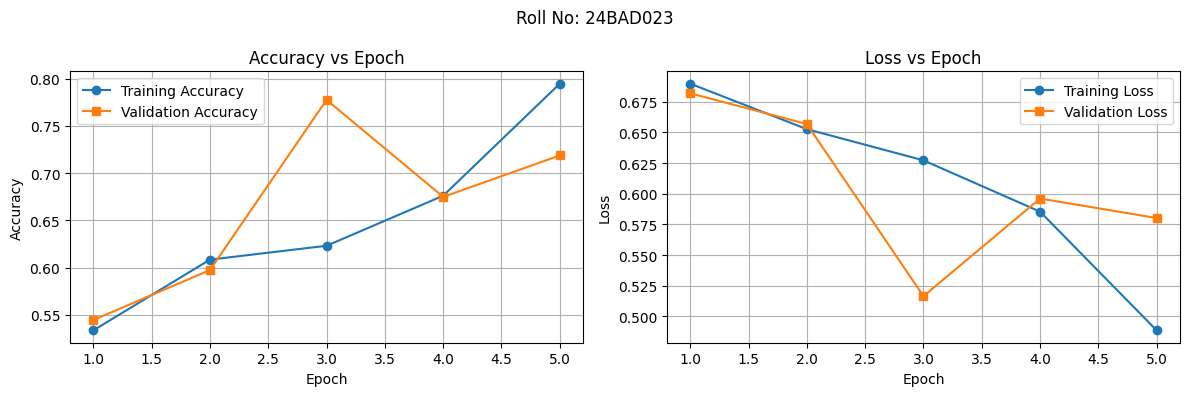

In [ ]:
# Accuracy vs Epoch and Loss vs Epoch
epochs = range(1, len(hist) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, hist["accuracy"], "o-", label="Training Accuracy")
ax[0].plot(epochs, hist["val_accuracy"], "s-", label="Validation Accuracy")
ax[0].set_title("Accuracy vs Epoch"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].legend(); ax[0].grid(True)

ax[1].plot(epochs, hist["loss"], "o-", label="Training Loss")
ax[1].plot(epochs, hist["val_loss"], "s-", label="Validation Loss")
ax[1].set_title("Loss vs Epoch"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].legend(); ax[1].grid(True)

plt.suptitle(f"Roll No: {', '.join(ROLL_NO)}")
plt.tight_layout(); plt.show()

Test Loss: 0.5209 | Test Accuracy: 0.7714

Accuracy : 0.7714
Precision: 0.8088
Recall   : 0.7109
F1-score : 0.7567

Classification Report:
               precision    recall  f1-score   support

    Negative       0.74      0.83      0.78     12500
    Positive       0.81      0.71      0.76     12500

    accuracy                           0.77     25000
   macro avg       0.78      0.77      0.77     25000
weighted avg       0.78      0.77      0.77     25000



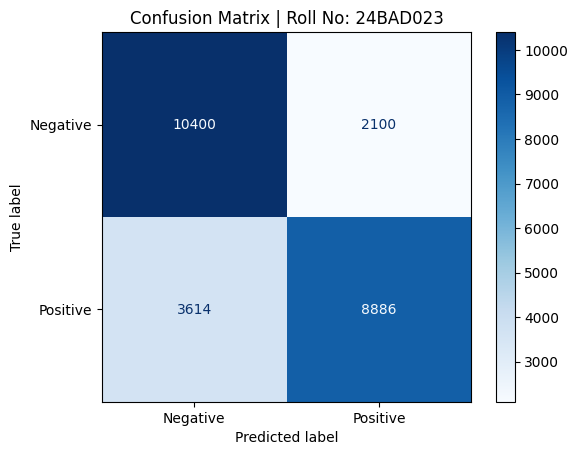

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

# Evaluate on test dataset
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}")

y_prob = model.predict(x_test, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("\nAccuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("\nClassification Report:\n",
      classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"])
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix | Roll No: {', '.join(ROLL_NO)}")
plt.show()

## PART D: Sentiment Prediction on New Reviews

In [ ]:
print("Roll No:", ROLL_NO)

def predict_sentiment(review):
    seq = text_to_sequence(review)                                   # same vocabulary as training
    pad = pad_sequences([seq], maxlen=MAX_LEN, padding="post", truncating="post")
    prob = float(model.predict(pad, verbose=0)[0][0])
    return ("Positive" if prob >= 0.5 else "Negative"), prob

samples = [
    ("This movie was absolutely fantastic, I loved every minute of it", "Positive"),
    ("A brilliant story with wonderful acting and a beautiful ending", "Positive"),
    ("One of the best films I have seen this year, highly recommended", "Positive"),
    ("The film was terrible, boring and a complete waste of time", "Negative"),
    ("Awful script and bad acting, I hated it", "Negative"),
    ("Very disappointing and dull, I almost fell asleep", "Negative"),
    ("The plot was predictable but the performances were good", "Positive"),
    ("It was not good at all", "Negative"),
]

rows = []
for text, expected in samples:
    pred, prob = predict_sentiment(text)
    rows.append({"Review": text, "Expected": expected, "Predicted": pred,
                 "Probability(Positive)": round(prob, 4),
                 "Correct": "Yes" if pred == expected else "No"})

results = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 80)
display(results)
print(f"\nCorrect predictions: {(results['Correct'] == 'Yes').sum()} / {len(results)}")

Roll No: ['24BAD023']


,Review,Expected,Predicted,Probability(Positive),Correct
0,"This movie was absolutely fantastic, I loved every minute of it",Positive,Negative,0.2590,No
1,A brilliant story with wonderful acting and a beautiful ending,Positive,Positive,0.8882,Yes
2,"One of the best films I have seen this year, highly recommended",Positive,Positive,0.8882,Yes
3,"The film was terrible, boring and a complete waste of time",Negative,Negative,0.2590,Yes
4,"Awful script and bad acting, I hated it",Negative,Negative,0.2590,Yes
5,"Very disappointing and dull, I almost fell asleep",Negative,Negative,0.2590,Yes
6,The plot was predictable but the performances were good,Positive,Negative,0.2590,No
7,It was not good at all,Negative,Negative,0.2590,Yes



Correct predictions: 6 / 8
